# REPAIR parameter research — 2026-10-19
## tl;dr
Proposal pending user confirmation: r_TP = **0.002 USDC / original share / second**;
SL = adverse 2-second move above both 2 ticks and 1.5 pre-event sigma, **or**
price-contribution drawdown >= **0.06 / original share**; force SL at T180.

These are auditable starting values. They are **not an EV optimum or a live-readiness certification**.
The existing TP formula frequently arms TP very early. Among unpaired probes the proposed SL is aggressive:
median holding age at path SL is 10 seconds, and 28.37% of 624 complete follow-ups recover the reference within 10 seconds.


## Context & Methods
### Key Assumptions
- Keep accepted HD → SL / HD → TP → SL, Buy Only, Maker Only, no fees, session $15 / |Delta| <= 5, T120/T180/T240 rules.
- Mark probability is YES midpoint and NO complement. Sigma is price per sqrt(second), as known **before** the event.
- 704 standardized price paths across **47 market clusters**, not 704 independent fixed-NORMAL fills. Entry T40..110 every 10s, both directions, 5 shares.
- Fair-cost and best-bid-cost alternatives are separate sensitivity probes. Bid entry is hypothetical, with no assumption that a resting order actually filled.
- Invalid/generation-changing paths are censored, not interpolated. The grid conservatively excludes endpoint books.
- A later ask <= fixed TP bid is a **quote-cross opportunity**, not a fill or a realized-profit label. The probe does not assume exits at these opportunities.
- 38 older-NORMAL opening anchors are supplementary. Current fixed-NORMAL 13 episodes are an economic scale check from different markets.
- First 31 markets / later 16 markets give chronological signal sensitivity; no independently validated EV claim.

Source lineage: `raw_manifest.json` hashes the 47 raw streams; `evidence.json` records cached data and economic sources.
To rebuild from the original local archive first run `python extract.py` (reads ~21 GB). The following cells recompute all candidate results from the included causal caches, then validate primary fill economics.


## Data
### 1. Recompute and check evidence

In [1]:
import os, sys, json, csv, subprocess
from pathlib import Path
os.environ['OPENBLAS_NUM_THREADS'] = '1'
import numpy as np
import matplotlib.pyplot as plt
D = Path.cwd()
assert (D/'analyze.py').exists()
completed = subprocess.run([sys.executable, 'analyze.py'], check=True, capture_output=True, text=True)
checked = subprocess.run([sys.executable, 'validate.py'], check=True, capture_output=True, text=True)
E = json.loads((D/'evidence.json').read_text())
print(json.dumps(E['scope'], indent=2))
print(checked.stdout)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white'})


{
  "markets": 47,
  "standardized_fair_cases": 704,
  "old_actual_opening_anchors": 38,
  "actual_fixed_normal_episodes": 13,
  "raw_bytes": 21155061498,
  "raw_events": 17571689,
  "grid_valid": 10045,
  "grid_sigma_valid": 8879,
  "archive_comparison": {
    "archive_valid": 10054,
    "raw_valid": 10047,
    "p_exact_match": 10047,
    "p_different": 0
  },
  "issues": {
    "dropped_flag_rows": 0
  }
}
{"status": "PASS", "cases_checked": 78084, "market_clusters": 47, "source_quote_comparisons_exact": 10047, "source_quote_comparisons_different": 0, "fixed_normal_episodes_economics_checked": 13, "raw_fixed_normal_journals_read": 10, "checks": ["unique market/case identity", "recorded source hashes", "causal event order", "TP rate monotonicity", "SL independence of TP rate without assumed fills", "censoring and quote-cross ordering", "primary confirmed opening and repair legs"]}



## Results
### 2. TP rate changes arming frequency; it does not establish EV
All-path rates below use the fixed-0.06 SL candidate. Dashed lines use the later 16 markets.
Overlapping paths are clustered by market for uncertainty; the exact table is path-weighted.


r_TP      fair all   fair later16   bid-cost all
0.0005      68.32%       67.72%         82.53%
0.0010      67.19%       67.72%         82.24%
0.0020      63.21%       63.78%         80.82%
0.0030      61.22%       62.60%         79.55%
0.0050      51.42%       53.15%         55.97%
0.0100      35.80%       38.19%         45.60%


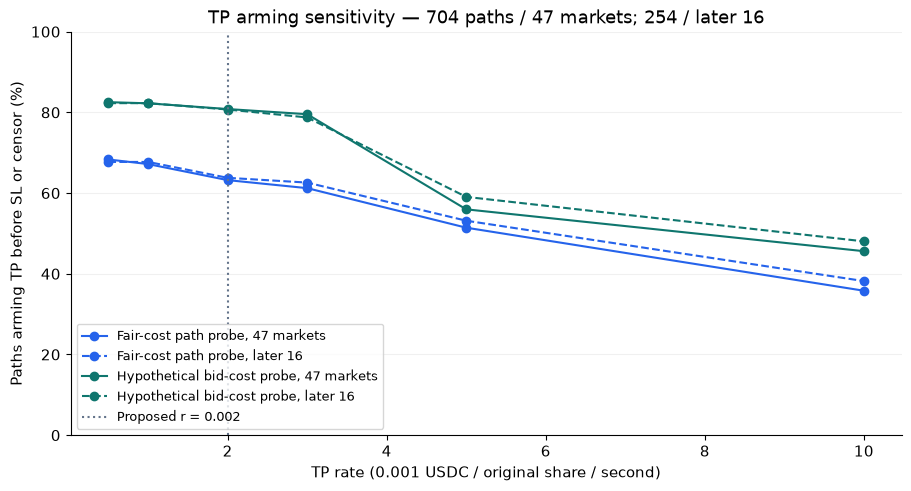

In [2]:
rates = E['r_grid']
def candidate(basis, split, spec, rate):
    return E['candidates'][f'{basis}|{split}|{spec}|{rate}']
print('r_TP      fair all   fair later16   bid-cost all')
for rate in rates:
    values = [candidate(b,s,'fixed06',rate)['tp_first_pct'] for b,s in
              [('fair','all'),('fair','chronological_check_16'),('best_bid','all')]]
    print(f'{rate:0.4f}     {values[0]:6.2f}%      {values[1]:6.2f}%        {values[2]:6.2f}%')
fig, ax = plt.subplots(figsize=(9,4.8), layout='constrained')
for basis, color, label in [('fair','#2563eb','Fair-cost path probe'),
                             ('best_bid','#0f766e','Hypothetical bid-cost probe')]:
    for split, ls, suffix in [('all','-','47 markets'),('chronological_check_16','--','later 16')]:
        ax.plot(np.array(rates)*1000,
                [candidate(basis,split,'fixed06',r)['tp_first_pct'] for r in rates],
                marker='o', color=color, linestyle=ls, label=f'{label}, {suffix}')
ax.axvline(2, color='#64748b', linestyle=':', label='Proposed r = 0.002')
ax.set(xlabel='TP rate (0.001 USDC / original share / second)',
       ylabel='Paths arming TP before SL or censor (%)', ylim=(0,100),
       title='TP arming sensitivity — 704 paths / 47 markets; 254 / later 16')
ax.grid(axis='y', alpha=.18)
ax.legend(fontsize=9, loc='lower left')
fig.savefig(D/'tp_rate_sensitivity.png', dpi=170)
plt.show()


At r=0.002, TP-first is 63.21% (fair cost) versus 80.82% (hypothetical bid cost).
Early TP within 2 seconds is 42.05% versus 72.87% of all probes. TP is an intent to wait at a favorable opposite-side price;
these figures do not mean immediate position closure. No extra cooldown was introduced.
The market-equal bootstrap interval for fair-cost TP-first is 59.36%–65.63%, distinct from the path-weighted point estimate.


### 3. Faster SL comes with recovery opportunities forgone
All three candidates use the same fast-shock rule. The chart assumes the original exposure is still unpaired,
even after TP arms; it never treats a quote crossing as a fill. Medians condition on path SL.
Recovery is measured only when all 10 subsequent seconds are valid, with different eligible counts shown below.


fixed04 {'path_sl_pct': 91.76136363636364, 'path_sl_age_median': 7.0, 'post_sl_10s_known_n': 639, 'recovered_pre_sl_10s_pct': 31.92488262910798}
fixed06 {'path_sl_pct': 89.48863636363636, 'path_sl_age_median': 10.0, 'post_sl_10s_known_n': 624, 'recovered_pre_sl_10s_pct': 28.365384615384617}
fixed08 {'path_sl_pct': 88.7784090909091, 'path_sl_age_median': 12.0, 'post_sl_10s_known_n': 619, 'recovered_pre_sl_10s_pct': 27.140549273021}


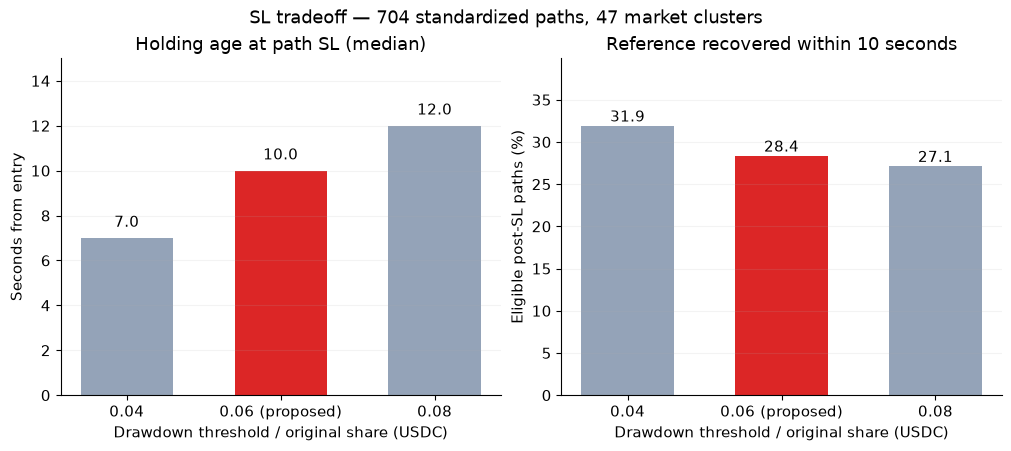

In [3]:
specs = ['fixed04','fixed06','fixed08']
v = [candidate('fair','all',s,.002) for s in specs]
for name, a in zip(specs,v):
    print(name, {k:a[k] for k in ['path_sl_pct','path_sl_age_median',
                                  'post_sl_10s_known_n','recovered_pre_sl_10s_pct']})
fig, axes = plt.subplots(1,2,figsize=(10,4.4),layout='constrained')
labels = ['0.04','0.06 (proposed)','0.08']
colors = ['#94a3b8','#dc2626','#94a3b8']
for ax, metric, ylabel, title in [
    (axes[0],'path_sl_age_median','Seconds from entry','Holding age at path SL (median)'),
    (axes[1],'recovered_pre_sl_10s_pct','Eligible post-SL paths (%)','Reference recovered within 10 seconds')]:
    vals = [a[metric] for a in v]
    ax.bar(labels,vals,color=colors,width=.6)
    for i,value in enumerate(vals): ax.text(i,value+.5,f'{value:.1f}',ha='center')
    ax.set(xlabel='Drawdown threshold / original share (USDC)',ylabel=ylabel,title=title,
           ylim=(0,max(vals)*1.25))
    ax.grid(axis='y',alpha=.15)
fig.suptitle('SL tradeoff — 704 standardized paths, 47 market clusters',fontsize=13)
fig.savefig(D/'sl_threshold_tradeoff.png',dpi=170)
plt.show()


The proposed 0.06 candidate reaches path SL on 89.49% of still-unpaired probes (96.06% in the later 16 markets).
The median holding age is 10 seconds in both groups. It is an **aggressive exit policy**, not a rare-event detector.
28.37% of 624 complete follow-ups recover the reference, while 76.92% worsen by at least a tick; these events can overlap.
Neither outcome proves that an executable SL adds or subtracts EV.


### 4. Reproduce the known 10→11 shock with pre-event sigma

In [4]:
C = list(csv.DictReader((D/'special_case.csv').open()))
shock = next(r for r in C if r['fast_z15']=='True')
assert int(shock['decision']) == 11
assert abs(float(shock['z'])-1.6418829792458165)<1e-9
assert float(shock['dd']) < .06
print({k:shock[k] for k in ['decision','t','p','previous_h','adverse','z','dd','no_bid','no_ask']})
print('Would enter / upgrade to SL if still unpaired; current positive PnL does not veto SL.')
print('Illustrative fresh SL order: NO 5 @ (0.38 - 0.01) = 0.37, subject to current inventory / constraints.')
assert 2.5 * .02 / 5 == .01 # partial remaining Delta, original Q0 unchanged


{'decision': '11', 't': '70.0499758720398', 'p': '0.625', 'previous_h': '2.636608839035034', 'adverse': '0.050000000000000044', 'z': '1.6418829792458165', 'dd': '0.050000000000000044', 'no_bid': '0.37', 'no_ask': '0.38'}
Would enter / upgrade to SL if still unpaired; current positive PnL does not veto SL.
Illustrative fresh SL order: NO 5 @ (0.38 - 0.01) = 0.37, subject to current inventory / constraints.


## Takeaways
- Recommend **r_TP=0.002**, **2-second / 1.5 pre-sigma / 2-tick shock**, **0.06/share price-contribution drawdown** as a simple SL-priority starting design.
- Both TP and SL often arm early. Preserve fixed-price TP waiting, mandatory TP→SL order handoff, and independent T180/T240 timers.
- In production accumulate actual episode Delta * dp / original Q0 between fills; never substitute total marked-PnL changes caused by buying.
- A reliable segment's own drawdown is a lower bound on the full-episode drawdown after a data gap; do not splice an unknown gap as zero.
- **Do not set live-ready or REPLAY_VALIDATED from this research.** Event-level replay, execution/late-fill behavior, session payoff and crash continuation remain separate validation work.
- Research provenance and complete candidate table accompany this notebook. The final reviewable design is `../../REPAIR_PARAMETER_PROPOSAL_20261019.md`.

Methods context: [NIST sequential monitoring](https://www.itl.nist.gov/div898/handbook/pmc/section3/pmc323.htm),
[Kaminski & Lo: stop-loss value depends on the return process](https://dspace.mit.edu/entities/publication/bb69ca4b-0cdc-487f-831d-63b2e84fafee).
